In [1]:
"""
downscaling_model_analysis.py
==============================
Self-contained analysis and visualisation of AI climate downscaling models.
Produces 4 figures and 2 tables comparing compute efficiency against
downscaling performance.

Performance metrics used (ESD pseudo-reality, cross-validation AV):
  - PR  Mean_bias  (mm/day, lower = better)
  - PR  RX1DAY_bias (mm,     lower = better)
  - TAS Mean_bias  (°C,     lower = better)
  - TAS TXX_bias   (°C,     lower = better)

Requires:
  pip install pdfplumber openpyxl pandas numpy matplotlib

Usage:
  Place all 4 PDF scorecards and Architecture_configurations.xlsx in the
  same folder as this script, then run:
      python downscaling_model_analysis.py
"""

import re
import warnings
import os
import pdfplumber
import openpyxl
import numpy as np
import pandas as pd
import matplotlib
#matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore")

# ──────────────────────────────────────────────────────────────────────────────
# 0.  PATHS  (edit if files live elsewhere)
# ──────────────────────────────────────────────────────────────────────────────
DATA_DIR  = os.getcwd()#path.dirname(os.path.abspath(__file__))
#OUT_DIR   = os.path.join(DATA_DIR, "outputs")
#os.makedirs(OUT_DIR, exist_ok=True)

PDF_PR_ESD    = os.path.join(DATA_DIR, "pr_esd_pseudo_reality_perfect_cross_validation_vs_pr_esd_pseudo_reality_perfect_extrapolation_scorecard.pdf")
PDF_PR_EMUL   = os.path.join(DATA_DIR, "pr_emulator_hist_future_perfect_cross_validation_vs_pr_emulator_hist_future_perfect_interpolation_scorecard.pdf")
PDF_TAS_ESD   = os.path.join(DATA_DIR, "tasmax_esd_pseudo_reality_perfect_cross_validation_vs_tasmax_esd_pseudo_reality_perfect_extrapolation_scorecard.pdf")
PDF_TAS_EMUL  = os.path.join(DATA_DIR, "tasmax_emulator_hist_future_perfect_cross_validation_vs_tasmax_emulator_hist_future_perfect_interpolation_scorecard.pdf")
XLSX_FILE     = os.path.join(DATA_DIR, "Architecture_configurations.xlsx")


In [2]:
z1 = [4.1, 5.32, 8.24, 5.89, 0.15, 0.28, 0.67, 0.37, 1.28, 1.48, 3.03, 1.93, 14.73, 25.14, 58.38, 32.75, 0.08, 0.05, 0.17, 0.1, 12.45, 19.96, 220.87, 84.43, 0.03, 0.02, 0.06, 0.04]

In [87]:
len(z1)

28

In [102]:

# ──────────────────────────────────────────────────────────────────────────────
# 1.  PDF EXTRACTION
# ──────────────────────────────────────────────────────────────────────────────
# Models appear in this fixed order across all 4 PDFs (37 total)
ALL_MODELS = [
    "DeepESD-IFCAv1",        "DeepESD-IFCAv1-orog",
    "DeepESDcrps_IFCAv2",    "DeepESDcrps_IFCAv2-orog",
    "ViT-IFCAv1",            "ViT-IFCAv1-orog",
    "FlowMatching-v1",       "FlowMatching-v1-orog",
    "ANN",                   "ANN-orog",
    "UiBCorrDiff-orog",      "RCMGEM-mv-orog",
    "CorrDiff-TW1_NTNU-CWA", "CorrDiff-TW1_NTNU-CWA-orog",
    "Prithvi-UNet",          "Prithvi-UNet-orog",
    "XGBoost_IDL",           "DeepESD_IDL",
    "deepsensor_bas",        "deepsensor_orog_bas",
    "ResGAN",                "ResGAN-orog",
    "CNRM-UNeT",
    "Rossby-UNet",           "Rossby-UNet-orog",
    "EnScale",               "EnScale-orog",   "EnScale-linex",
    "spaGAN",                "spaGAN-orog",
    "DetUNet",               "DetUNet-orog",
    "ParamUNET",
    "ResGAN-v2",             "ResGAN-v2-orog",
    "DetUNet-v2",            "DetUNet-v2-orog",
]
def extract_metric_av(pdf_path: str, metric_idx: int) -> dict:
    """Return {model: (cv_AV, ex_AV)} for one metric from one scorecard PDF."""
    with pdfplumber.open(pdf_path) as pdf:
        nums = [float(x) for x in re.findall(r"\d+\.\d+", pdf.pages[0].extract_text())]
    out = {}
    for m_idx, model in enumerate(ALL_MODELS):
        row = nums[m_idx * 56 : m_idx * 56 + 56]
        #print(row)
        row2 = np.array(row).reshape(28, 2, order ='F')[:,1]
        row1 = np.array(row).reshape(28, 2, order ='F')[:,0]
        #print(row[:,0])
        if metric_idx ==2:
            cv_av = row1[11]#28 + 4 * metric_idx + 1]
            ex_av = row2[11]#28 + 4 * metric_idx + 3]
        else:
            cv_av = row1[15]#28 + 4 * metric_idx + 1]
            ex_av = row2[15]#28 + 4 * metric_idx + 3]  
        #print(cv_av, ex_av, model, m_idx)
        out[model] = (cv_av, ex_av)
    return out
 
 
print("Extracting metrics from PDFs …")
pr_meanbias  = extract_metric_av(PDF_PR_ESD,   1)   # PR  Mean_bias,   ESD
pr_rx1day    = extract_metric_av(PDF_PR_ESD,   3)   # PR  RX1DAY_bias, ESD
tas_meanbias = extract_metric_av(PDF_TAS_ESD,  1)   # TAS Mean_bias,   ESD
tas_txx      = extract_metric_av(PDF_TAS_ESD,  2)   # TAS TXX_bias,    ESD
 
# Also pull emulator experiment for the four-panel comparison figure
pr_meanbias_em  = extract_metric_av(PDF_PR_EMUL,  1)
pr_rx1day_em    = extract_metric_av(PDF_PR_EMUL,  3)
tas_meanbias_em = extract_metric_av(PDF_TAS_EMUL, 1)
tas_txx_em      = extract_metric_av(PDF_TAS_EMUL, 2)
 
# Build performance dataframe (base models preferred; -orog noted separately)
perf_rows = []
for model in ALL_MODELS:
    perf_rows.append({
        "model":           model,
        "pr_esd_mb":       pr_meanbias[model][1],
        "pr_esd_rx1day":   pr_rx1day[model][1],
        "tas_esd_mb":      tas_meanbias[model][1],
        "tas_esd_txx":     tas_txx[model][1],
        "pr_emul_mb":      pr_meanbias_em[model][1],
        "pr_emul_rx1day":  pr_rx1day_em[model][1],
        "tas_emul_mb":     tas_meanbias_em[model][1],
        "tas_emul_txx":    tas_txx_em[model][1],
    })
df_perf = pd.DataFrame(perf_rows)

Extracting metrics from PDFs …


In [17]:
df_perf

,model,pr_esd_mb,pr_esd_rx1day,tas_esd_mb,tas_esd_txx,pr_emul_mb,pr_emul_rx1day,tas_emul_mb,tas_emul_txx
0,DeepESD-IFCAv1,2.50,2.50,1.99,1.99,1.51,1.51,0.61,0.61
1,DeepESD-IFCAv1-orog,2.12,2.12,0.79,0.79,1.52,1.52,0.58,0.58
2,DeepESDcrps_IFCAv2,1.16,1.16,7.22,7.22,0.77,0.77,1.89,1.89
3,DeepESDcrps_IFCAv2-orog,0.87,0.87,1.64,1.64,1.01,1.01,1.20,1.20
4,ViT-IFCAv1,1.28,1.28,1.60,1.60,1.25,1.25,0.70,0.70
5,ViT-IFCAv1-orog,1.39,1.39,1.57,1.57,0.97,0.97,0.70,0.70
6,FlowMatching-v1,1.87,1.87,1.85,1.85,1.08,1.08,0.55,0.55
7,FlowMatching-v1-orog,1.15,1.15,1.54,1.54,1.10,1.10,0.58,0.58
8,ANN,2.90,2.90,19.81,19.81,2.93,2.93,1.07,1.07
9,ANN-orog,2.85,2.85,1.20,1.20,3.03,3.03,0.95,0.95


In [101]:
df_perf

,model,pr_esd_mb,pr_esd_rx1day,tas_esd_mb,tas_esd_txx,pr_emul_mb,pr_emul_rx1day,tas_emul_mb,tas_emul_txx
0,DeepESD-IFCAv1,44.67,2.50,0.75,1.99,32.12,1.51,0.09,0.61
1,DeepESD-IFCAv1-orog,44.75,2.12,0.12,0.79,33.71,1.52,0.09,0.58
2,DeepESDcrps_IFCAv2,41.02,1.16,0.72,7.22,18.98,0.77,0.08,1.89
3,DeepESDcrps_IFCAv2-orog,43.94,0.87,0.20,1.64,35.64,1.01,0.10,1.20
4,ViT-IFCAv1,22.16,1.28,0.29,1.60,14.26,1.25,0.08,0.70
5,ViT-IFCAv1-orog,24.85,1.39,0.34,1.57,15.02,0.97,0.08,0.70
6,FlowMatching-v1,20.83,1.87,0.18,1.85,16.01,1.08,0.08,0.55
7,FlowMatching-v1-orog,16.83,1.15,0.18,1.54,16.98,1.10,0.08,0.58
8,ANN,57.72,2.90,1.38,19.81,54.11,2.93,0.11,1.07
9,ANN-orog,57.28,2.85,0.15,1.20,55.01,3.03,0.11,0.95


In [105]:


# ──────────────────────────────────────────────────────────────────────────────
# 2.  COMPUTE & ARCHITECTURE DATA
# ──────────────────────────────────────────────────────────────────────────────
# Normalise training time to "A100-equivalent GPU-hours" for fair comparison.
# GPU speed relative to 1× A100 (FP32 throughput basis).
GPU_SPEED = {
    "H200": 4.0, "H100": 3.0, "GH200": 3.0,
    "A100": 1.0, "A40": 0.55, "A30": 0.43,
    "V100": 0.30, "RTX6000": 0.17, "A10": 0.20,
    "CPU": 0.01,
}

# Parameters: (value_M, is_estimate)
# Estimates marked with ~ and sourced from architecture descriptions.
PARAMS = {
    # ── Known from Excel ──────────────────────────────────────────────────────
    "Rossby-UNet":           (3.16,  False),  # 3,157,491
    "DetUNet":               (2.70,  False),  # ~2.7M from sheet
    "CNRM-UNeT":             (6.30,  False),  # ~6,300,000
    "Prithvi-UNet":          (254.4, False),  # 254,372,782
    "DeepESD_IDL":           (49.2,  False),  # 49,221,827
    "XGBoost_IDL":           (0.20,  False),  # ~200,000
    "ResGAN":                (6.0,   False),  # ~6M
    "EnScale":               (40.0,  False),  # ~40M
    "EnScale-linex":         (103.0, False),  # ~40M net + ~63M linear
    "UiBCorrDiff-orog":      (158.0, False),  # 78M UNet + 79M diffusion
    "CorrDiff-TW1_NTNU-CWA": (157.0, False), # same architecture as UiB
    "RCMGEM-mv-orog":        (63.0,  False),  # ~63M from sheet
    # ── Estimated from architecture descriptions ──────────────────────────────
    "DeepESD-IFCAv1":        (10,  True),   # 3 conv + 1 dense CNN, typical ~0.5M
    "DeepESDcrps_IFCAv2":    (10,  True),   # same architecture as DeepESD
    "ViT-IFCAv1":            (50.0,  True),   # small ViT, ~10M typical
    "FlowMatching-v1":       (50, True),   # ADM-style U-Net backbone ~100M
    "ANN":                   (8,  True),   # 2-layer MLP, ~50K
    "deepsensor_bas":        (50.0,   True),   # neural process, ~5M
    "spaGAN":                (10,   True),   # UNet2D GAN, similar to ResGAN
    "ParamUNET":             (8.9,   True),   # U-Net outputting dist params
    "ResGAN-v2":             (6.0,   True),   # same arch as ResGAN
    "DetUNet-v2":            (2.7,   True),   # same arch as DetUNet
}

# Main compute table: (gpu, n_gpus, total_train_h, infer_s_per_year, model_type, institution)
# train_h: best mid-point estimate from documentation
# need to check the training time of ANN
#DeepESD, DeepESDCRPS, and VIT are made up
#Deepesd estimate
# ""Multiply training and compute by 2 for other approaches since they are not multiple variate. 
COMPUTE = {
    "DeepESD-IFCAv1":        ("V100",    1, 2,    0.5,   "Det", "IFCA", "Uni"),
    "DeepESDcrps_IFCAv2":    ("V100",    2, 5,    1,   "Det", "IFCA", "Uni"),
    "ViT-IFCAv1":            ("V100",    2, 15,    50,   "Det", "IFCA", "Multi"),
    "FlowMatching-v1":       ("H100",    1, 0.75,    150.0,  "Gen", "Met Office","Multi"),
    "ANN":                   ("CPU",     1, 0.58,    1,  "Det", "BSC","Uni"),
    "UiBCorrDiff-orog":      ("GH200",   1, 8.00,    228.0,  "Gen", "UiB","Multi"),
    "RCMGEM-mv-orog":        ("A100",    1, 30,   1800.0, "Gen", "UoB","Multi"),
    "CorrDiff-TW1_NTNU-CWA": ("H200",   8, 17.5,   270.0,  "Gen", "NTNU-CWA","Multi"),
    "Prithvi-UNet":          ("A10",     4, 60,   360.0,  "Det", "JPL","Multi"),
    "XGBoost_IDL":           ("A100",    1, 25.00,   300, "Det", "IDL","Uni"),
    "DeepESD_IDL":           ("A100",    1, 0.40,    1, "Det", "IDL","Multi"),
    "deepsensor_bas":        ("A100",    1, 12.00,   90.0,   "Det", "BAS","Uni"),
    "ResGAN":                ("A100",    1, 8.40,    1.0,    "Gen", "ESNZ","Uni"),
    "CNRM-UNeT":             ("A30",     1, 1.25,    1.5,   "Det", "CNRM","Uni"),
    "Rossby-UNet":           ("A40",     1, 0.21,    1.0,    "Det", "SMHI","Uni"),
    "EnScale":               ("RTX6000", 1, 4.00,    0.06,    "Gen", "ETH Zurich","Uni"),
    "EnScale-linex":         ("RTX6000", 1, 7.00,    0.06,    "Gen", "ETH Zurich","Uni"),
    "spaGAN":                ("V100",    1, 10.00,   2.25,   "Gen", "KIT","Uni"),
    "DetUNet":               ("A100",    1, 12.00,   0.5,    "Det", "ESNZ","Uni"),
    "ParamUNET":             ("V100",    1, 0.50,    1.0,    "Det", "LSCE-IPSL","Uni"),
    "ResGAN-v2":             ("A100",    1, 24,    1.0,    "Gen", "ESNZ","Uni"),
    "DetUNet-v2":            ("A100",    1, 6,   0.5,    "Det", "ESNZ","Uni"),
}

# ──────────────────────────────────────────────────────────────────────────────
# 3.  MERGE INTO MASTER DATAFRAME  (base models only for main plots)
# ──────────────────────────────────────────────────────────────────────────────
rows = []
for model, (gpu, n_gpu, train_h, infer_s, mtype, inst, multi) in COMPUTE.items():
    prow = df_perf[df_perf["model"] == model].iloc[0]
    speed = GPU_SPEED.get(gpu, 1.0)
    a100h = train_h# * speed * n_gpu
    if multi == "Uni":
        a100h = a100h * 2
        infer_s = infer_s * 2
    param_val, param_est = PARAMS.get(model, (None, None))
    rows.append({
        "model":        model,
        "institution":  inst,
        "type":         mtype,
        "gpu":          gpu,
        "n_gpu":        n_gpu,
        "train_h":      train_h,
        "a100_h":       a100h,
        "infer_s":      infer_s,
        "params_M":     param_val,
        "params_est":   param_est,
        # ESD pseudo-reality (primary)
        "pr_mb":        prow["pr_esd_mb"],
        "pr_rx1day":    prow["pr_esd_rx1day"],
        "tas_mb":       prow["tas_esd_mb"],
        "tas_txx":      prow["tas_esd_txx"],
        # Emulator (secondary)
        "pr_mb_em":     prow["pr_emul_mb"],
        "pr_rx1day_em": prow["pr_emul_rx1day"],
        "tas_mb_em":    prow["tas_emul_mb"],
        "tas_txx_em":   prow["tas_emul_txx"],
    })

df = pd.DataFrame(rows)

In [106]:
df.index = df.model

In [95]:


df['pr_rx1day_em']

model
DeepESD-IFCAv1           1.51
DeepESDcrps_IFCAv2       0.77
ViT-IFCAv1               1.25
FlowMatching-v1          1.08
ANN                      2.93
UiBCorrDiff-orog         3.37
RCMGEM-mv-orog           0.38
CorrDiff-TW1_NTNU-CWA    2.21
Prithvi-UNet             2.44
XGBoost_IDL              3.38
DeepESD_IDL              0.63
deepsensor_bas           2.44
ResGAN                   0.65
CNRM-UNeT                1.32
Rossby-UNet              2.83
EnScale                  0.80
EnScale-linex            2.55
spaGAN                   1.98
DetUNet                  1.73
ParamUNET                1.87
ResGAN-v2                0.65
DetUNet-v2               2.01
Name: pr_rx1day_em, dtype: float64

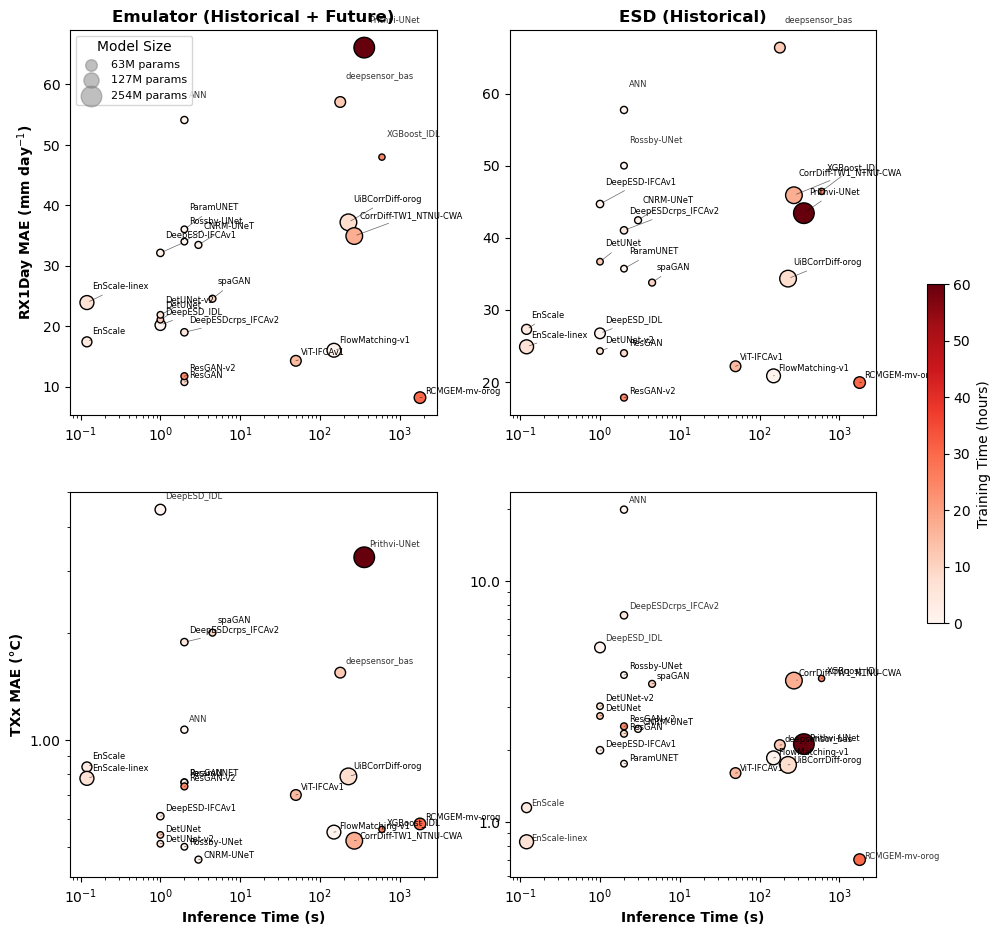

In [111]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as mticker

# --- helper: label placement with arrows if crowded ---
def add_labels(ax, x, y, labels, logy=False):
    x = np.array(x)
    y = np.array(y)

    order = np.argsort(y)

    dx = 0.15
    dy = np.linspace(0.01, 0.07, len(y))

    # detect "crowding" threshold
    y_range = np.max(y) - np.min(y)
    crowd_thresh = 0.05 * y_range if not logy else 0.1

    for i, idx in enumerate(order):
        xi = x[idx]
        yi = y[idx]

        # offset position
        if logy:
            yi_text = yi * (1 + dy[i])
        else:
            yi_text = yi + dy[i] * y_range

        xi_text = xi * (1 + dx)

        # check if close to another point → use arrow
        use_arrow = False
        for j in range(len(x)):
            if j != idx:
                if logy:
                    dist = abs(np.log(yi) - np.log(y[j]))
                else:
                    dist = abs(yi - y[j])
                if dist < crowd_thresh:
                    use_arrow = True
                    break

        if use_arrow:
            ax.annotate(
                labels[idx],
                xy=(xi, yi),
                xytext=(xi_text, yi_text),
                textcoords='data',
                fontsize=6,
                arrowprops=dict(arrowstyle='-', lw=0.5, alpha=0.6)
            )
        else:
            ax.text(
                xi_text,
                yi_text,
                labels[idx],
                fontsize=6,
                alpha=0.8
            )


# --- scale marker sizes (much nicer visually) ---
sizes = 20 + (df['params_M'] / df['params_M'].max()) * 200


# --- figure ---
fig, ax = plt.subplots(2, 2, figsize=(13, 11))

# ======================
# TOP LEFT
# ======================
sc = ax[0,0].scatter(df['infer_s'], df['pr_rx1day_em'],
                     c=df['train_h'], s=sizes, cmap ='Reds', vmin =0 ,vmax =60, ec ='k')

add_labels(ax[0,0], df['infer_s'], df['pr_rx1day_em'], df.index)

ax[0,0].set_xscale('log')
ax[0,0].set_ylabel('RX1Day MAE (mm day$^{-1}$)', weight='bold')
ax[0,0].set_title('Emulator (Historical + Future)', weight='bold')


# ======================
# TOP RIGHT
# ======================
ax[0,1].scatter(df['infer_s'], df['pr_rx1day'],
                c=df['train_h'], s=sizes,cmap ='Reds', vmin =0 ,vmax =60, ec ='k')

add_labels(ax[0,1], df['infer_s'], df['pr_rx1day'], df.index)

ax[0,1].set_xscale('log')
ax[0,1].set_title('ESD (Historical)', weight='bold')


# ======================
# BOTTOM LEFT
# ======================
ax[1,0].scatter(df['infer_s'], df['tas_txx_em'],
                c=df['train_h'], s=sizes, cmap ='Reds', vmin =0 ,vmax =60, ec ='k')

add_labels(ax[1,0], df['infer_s'], df['tas_txx_em'], df.index, logy=True)

ax[1,0].set_xscale('log')
ax[1,0].set_yscale('log')
ax[1,0].set_ylabel('TXx MAE (°C)', weight='bold')


# ======================
# BOTTOM RIGHT
# ======================
ax[1,1].scatter(df['infer_s'], df['tas_txx'],
                c=df['train_h'], s=sizes,cmap ='Reds', vmin =0 ,vmax =60, ec ='k')

add_labels(ax[1,1], df['infer_s'], df['tas_txx'], df.index, logy=True)

ax[1,1].set_xscale('log')
ax[1,1].set_yscale('log')


# ======================
# X-axis labels
# ======================
ax[1,0].set_xlabel('Inference Time (s)', weight='bold')
ax[1,1].set_xlabel('Inference Time (s)', weight='bold')


# ======================
# Clean log formatting
# ======================
for a in [ax[1,0], ax[1,1]]:
    a.yaxis.set_major_formatter(mticker.ScalarFormatter())
    a.yaxis.set_minor_formatter(mticker.NullFormatter())


# ======================
# Colorbar
# ======================
cbar = fig.colorbar(sc, ax=ax, shrink=0.4)
cbar.set_label('Training Time (hours)')


# ======================
# Size legend (NEW)
# ======================
for s_val in [0.25, 0.5, 1.0]:
    ax[0,0].scatter([], [], 
                    s=20 + s_val * 200, 
                    c='gray', alpha=0.5,
                    label=f'{int(s_val * df["params_M"].max())}M params')

ax[0,0].legend(title='Model Size', fontsize=8, loc='upper left')


#plt.tight_layout()
plt.show()
fig.savefig(r'/esi/project/niwa00018/rampaln/PUBLICATIONS/2026/CORDEX_ML_TF/Perfoamnce_vs_MAE.png', dpi =500, bbox_inches ='tight')

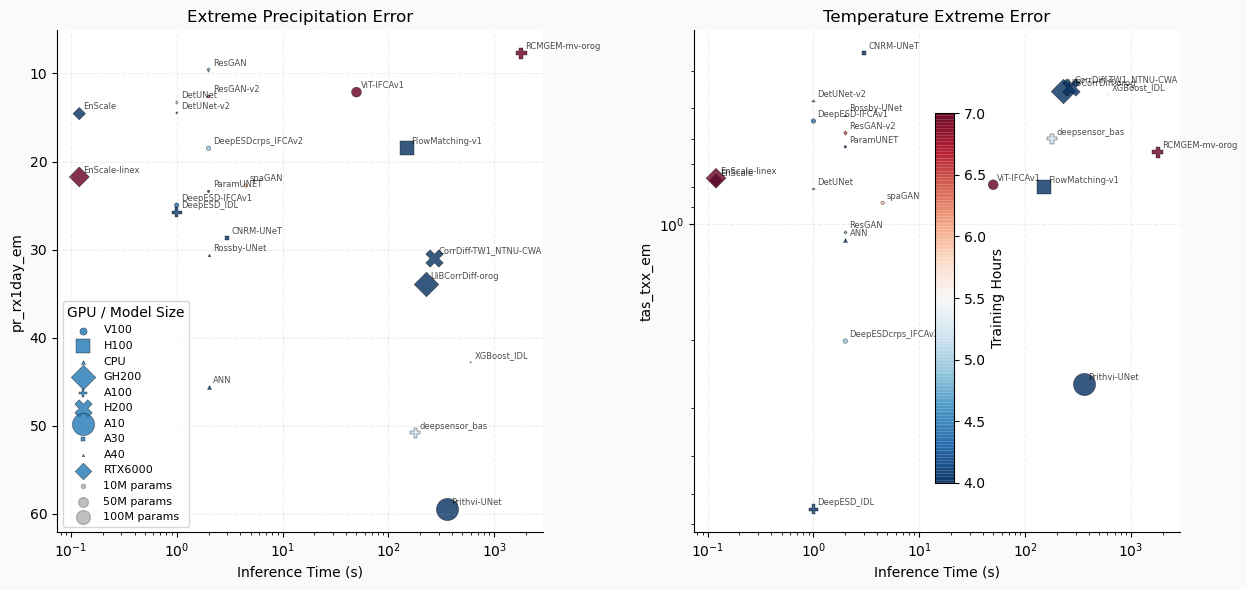

In [50]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# --- marker map for GPUs ---
gpu_types = df['gpu'].unique()
markers = ['o', 's', '^', 'D', 'P', 'X']
marker_map = {gpu: markers[i % len(markers)] for i, gpu in enumerate(gpu_types)}

# --- scatter plots ---
for gpu in gpu_types:
    sub = df[df['gpu'] == gpu]

    sc0 = ax[0].scatter(
        sub['infer_s'],
        sub['pr_rx1day_em'],
        c=sub['train_h'],
        s=sub['params_M'],
        cmap='RdBu_r',
        marker=marker_map[gpu],
        alpha=0.8,
        edgecolor='k',
        linewidth=0.3,
        label=gpu
    )

    sc1 = ax[1].scatter(
        sub['infer_s'],
        sub['tas_txx_em'],
        c=sub['train_h'],
        s=sub['params_M'],
        cmap='RdBu_r',
        marker=marker_map[gpu],
        alpha=0.8,
        edgecolor='k',
        linewidth=0.3
    )

# --- labels (slight smarter offset) ---
for label in df.index:
    x = df.loc[label]['infer_s']
    
    ax[0].annotate(
        label,
        (x, df.loc[label]['pr_rx1day_em']),
        xytext=(3, 3),
        textcoords="offset points",
        fontsize=6,
        alpha=0.7
    )
    
    ax[1].annotate(
        label,
        (x, df.loc[label]['tas_txx_em']),
        xytext=(3, 3),
        textcoords="offset points",
        fontsize=6,
        alpha=0.7
    )

# --- scales ---
for a in ax:
    a.set_xscale('log')
    #a.grid(True, which='both', linestyle='--', alpha=0.3)

ax[1].set_yscale('log')

# --- optional: invert y-axis (if "lower is better") ---
ax[0].invert_yaxis()
ax[1].invert_yaxis()

# --- labels ---
ax[0].set_title('Extreme Precipitation Error')
ax[0].set_xlabel('Inference Time (s)')
ax[0].set_ylabel('pr_rx1day_em')

ax[1].set_title('Temperature Extreme Error')
ax[1].set_xlabel('Inference Time (s)')
ax[1].set_ylabel('tas_txx_em')

# --- colorbar ---
cbar = fig.colorbar(sc1, ax=ax.ravel().tolist(), shrink=0.8)
cbar.set_label('Training Hours')

# --- GPU legend ---
ax[0].legend(title='GPU', fontsize=8)

# --- size legend (params_M) ---
for size in [10, 50, 100]:
    ax[0].scatter([], [], s=size, c='gray', alpha=0.5, label=f'{size}M params')
ax[0].legend(title='GPU / Model Size', fontsize=8)

plt.tight_layout()
plt.show()

In [11]:
metric_cols = ["pr_mb", "pr_rx1day", "tas_mb", "tas_txx"]
for col in metric_cols:
    df[f"pct_{col}"] = df[col].rank(pct=True)   # higher pct = worse for bias metrics
df["pct_score"] = df[[f"pct_{c}" for c in metric_cols]].mean(axis=1)
# Invert so 100 = best
df["perf_score"] = (1 - df["pct_score"]) * 100

print("Master dataframe built. Models included:", len(df))
print(df[["model","type","gpu","a100_h","params_M","params_est",
          "pr_mb","pr_rx1day","tas_mb","tas_txx","perf_score"]].sort_values("perf_score", ascending=False).to_string(index=False))


Master dataframe built. Models included: 22
                model type     gpu  a100_h  params_M  params_est  pr_mb  pr_rx1day  tas_mb  tas_txx  perf_score
       RCMGEM-mv-orog  Gen    A100   30.00     63.00       False   0.24      10.92    0.59     0.79   87.500000
        EnScale-linex  Gen RTX6000   14.00    103.00       False   0.34      28.61    0.43     0.53   81.818182
           ViT-IFCAv1  Det    V100   15.00     50.00        True   0.37      17.55    0.57     1.21   78.409091
       DeepESD-IFCAv1  Det    V100    4.00     10.00        True   0.42      37.78    0.40     0.65   72.727273
            ResGAN-v2  Gen    A100   48.00      6.00        True   0.33      12.60    0.77     2.30   71.022727
              EnScale  Gen RTX6000    8.00     40.00       False   0.33      23.93    1.07     0.88   67.613636
            ParamUNET  Det    V100    1.00      3.00        True   0.48      31.32    0.74     2.11   59.659091
      FlowMatching-v1  Gen    H100    0.75    100.00        

In [12]:


# ── Composite performance score (percentile rank, 0=worst 100=best) ──────────

# ──────────────────────────────────────────────────────────────────────────────
# 4.  STYLE CONSTANTS
# ──────────────────────────────────────────────────────────────────────────────
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.22, "grid.linestyle": "--",
    "figure.facecolor": "#FAFAFA",
})

TYPE_COLOR  = {"Det": "#2E86AB", "Gen": "#E84855"}
GPU_MARKER  = {
    "H200": "D", "H100": "D", "GH200": "^",
    "A100": "o", "A40":  "s", "A30": "p",
    "V100": "X", "RTX6000": "*", "A10": "h", "CPU": "v",
}
GPU_TIER_LABEL = {
    "H200": "H-series (≥3× A100)", "H100": "H-series (≥3× A100)",
    "GH200": "H-series (≥3× A100)", "A100": "A100",
    "A40": "A40/A30", "A30": "A40/A30",
    "V100": "V100", "RTX6000": "RTX/Consumer",
    "A10": "RTX/Consumer", "CPU": "CPU",
}
GOOD_BAD = LinearSegmentedColormap.from_list("gb", ["#2dc653", "#f5f5f5", "#e84855"])

# Short label helper
def short(name):
    return (name
            .replace("_NTNU-CWA", "").replace("_IDL", "")
            .replace("_bas", "").replace("-mv", ""))

# Legend handle helpers
def type_legend():
    return [mpatches.Patch(color=c, label=f"{t} model") for t, c in TYPE_COLOR.items()]

def gpu_legend(df_sub):
    gpus_present = df_sub["gpu"].unique()
    return [
        Line2D([0],[0], marker=GPU_MARKER[g], color="w", markerfacecolor="gray",
               markersize=8, markeredgecolor="k", label=GPU_TIER_LABEL[g])
        for g in GPU_MARKER if g in gpus_present
    ]

def annotate_scatter(ax, df_sub, xcol, ycol):
    for _, r in df_sub.iterrows():
        ax.annotate(
            short(r["model"]),
            (r[xcol], r[ycol]),
            fontsize=6.2, xytext=(4, 3), textcoords="offset points",
            color="#333333", zorder=5,
        )

def draw_scatter(ax, df_sub, xcol, ycol, size_by_params=False):
    for _, r in df_sub.iterrows():
        sz = 120
        if size_by_params and pd.notna(r["params_M"]):
            sz = 40 + 220 * min(np.log10(max(r["params_M"], 0.05) + 1) / np.log10(260), 1)
        ax.scatter(r[xcol], r[ycol],
                   c=TYPE_COLOR[r["type"]], marker=GPU_MARKER.get(r["gpu"], "o"),
                   s=sz, edgecolors="k", linewidths=0.6, zorder=4, alpha=0.88)
    annotate_scatter(ax, df_sub, xcol, ycol)

def pareto_line(ax, df_sub, xcol, ycol):
    """Draw dashed efficiency frontier (Pareto front, lower-left is better)."""
    ds = df_sub[[xcol, ycol]].dropna().sort_values(xcol)
    best, pts = np.inf, []
    for _, r in ds.iterrows():
        if r[ycol] < best:
            pts.append(r)
            best = r[ycol]
    if len(pts) > 1:
        fx = [p[xcol] for p in pts]
        fy = [p[ycol] for p in pts]
        ax.step(fx, fy, where="post", color="#555", ls="--", lw=1.3, zorder=2,
                label="Efficiency frontier")

# ──────────────────────────────────────────────────────────────────────────────
# 5.  FIGURE 1 — Efficiency frontier: compute vs bias metrics
# ──────────────────────────────────────────────────────────────────────────────
print("\nBuilding Figure 1: Efficiency frontier …")


Building Figure 1: Efficiency frontier …


In [14]:


# metric_pairs = [
#     ("pr_mb",     "PR Mean Bias (mm/day) ↓",     "Precipitation — Mean Bias"),
#     ("pr_rx1day", "PR RX1DAY Bias (mm) ↓",        "Precipitation — Extreme (RX1DAY)"),
#     ("tas_mb",    "TASMAX Mean Bias (°C) ↓",       "Temperature — Mean Bias"),
#     ("tas_txx",   "TASMAX TXX Bias (°C) ↓",        "Temperature — Extreme (TXX)"),
# ]

# fig, axes = plt.subplots(2, 2, figsize=(16, 12))
# fig.suptitle(
#     "Climate Downscaling: Training Compute vs Bias (ESD pseudo-reality, cross-validation AV)\n"
#     "Dashed line = efficiency frontier  |  Marker = GPU tier  |  Colour = model type",
#     fontsize=12, fontweight="bold",
# )
# axes = axes.flatten()

# df_plot = df[df["a100_h"] > 0].copy()

# for ax, (ycol, ylabel, title) in zip(axes, metric_pairs):
#     sub = df_plot[df_plot[ycol].notna()]
#     pareto_line(ax, sub, "a100_h", ycol)
#     draw_scatter(ax, sub, "a100_h", ycol, size_by_params=True)
#     ax.set_xscale("log")
#     ax.set_xlabel("Training Compute (A100-equiv GPU-hours, log scale)", fontsize=9)
#     ax.set_ylabel(ylabel, fontsize=9)
#     ax.set_title(title, fontweight="bold", fontsize=10)
#     ax.invert_yaxis()

# # Size legend (params)
# sz_handles = [
#     Line2D([0],[0], marker="o", color="w", markerfacecolor="#888",
#            markersize=s, markeredgecolor="k", label=lbl)
#     for s, lbl in [(4,"~0.05–0.5M"), (7,"~5–10M"), (10,"~40–100M"), (13,"~150–254M")]
# ]
# axes[0].legend(handles=type_legend() + gpu_legend(df_plot),
#                title="Type / GPU", fontsize=7, title_fontsize=8, ncol=2, loc="upper right")
# axes[1].legend(handles=sz_handles,
#                title="# Parameters (bubble size)", fontsize=7, title_fontsize=8, loc="upper right")

# plt.tight_layout()

Building Figure 2: Parameters vs performance …


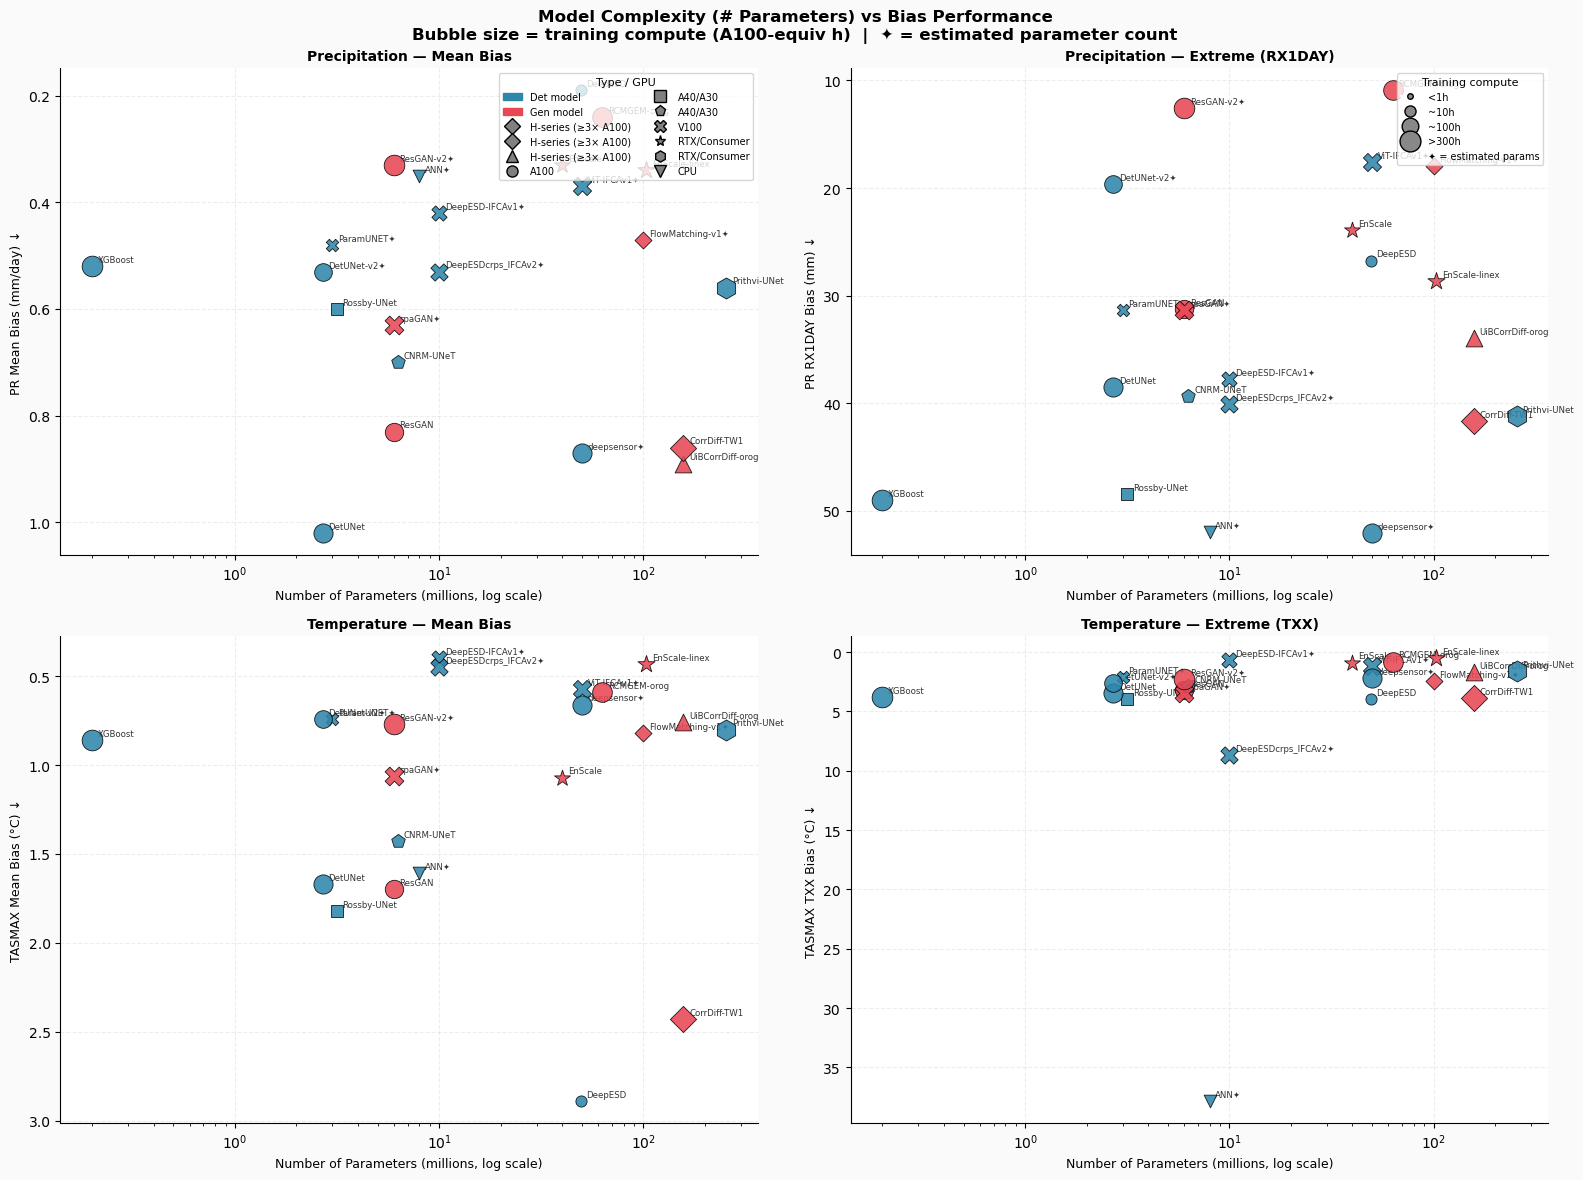

In [16]:

#fig.savefig(os.path.join(OUT_DIR, "fig1_efficiency_frontier.png"), dpi=160, bbox_inches="tight")
#plt.close()
#print("  → fig1_efficiency_frontier.png")

# ──────────────────────────────────────────────────────────────────────────────
# 6.  FIGURE 2 — Parameters vs performance (all 4 metrics)
# ──────────────────────────────────────────────────────────────────────────────
print("Building Figure 2: Parameters vs performance …")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(
    "Model Complexity (# Parameters) vs Bias Performance\n"
    "Bubble size = training compute (A100-equiv h)  |  ✦ = estimated parameter count",
    fontsize=12, fontweight="bold",
)
axes = axes.flatten()

df_params = df.copy()  # include all (estimated params are included)

for ax, (ycol, ylabel, title) in zip(axes, metric_pairs):
    sub = df_params[df_params[ycol].notna() & df_params["params_M"].notna()]
    # Bubble size = log training compute
    for _, r in sub.iterrows():
        sz = 50 + 280 * min(np.log1p(r["a100_h"]) / np.log1p(600), 1)
        marker = GPU_MARKER.get(r["gpu"], "o")
        ax.scatter(r["params_M"], r[ycol],
                   c=TYPE_COLOR[r["type"]], marker=marker, s=sz,
                   edgecolors="k", linewidths=0.6, zorder=4, alpha=0.88)
        # Mark estimated params with ✦
        suffix = "✦" if r["params_est"] else ""
        ax.annotate(short(r["model"]) + suffix,
                    (r["params_M"], r[ycol]),
                    fontsize=6.2, xytext=(4, 3), textcoords="offset points", color="#333")

    ax.set_xscale("log")
    ax.set_xlabel("Number of Parameters (millions, log scale)", fontsize=9)
    ax.set_ylabel(ylabel, fontsize=9)
    ax.set_title(title, fontweight="bold", fontsize=10)
    ax.invert_yaxis()

sz_handles2 = [
    Line2D([0],[0], marker="o", color="w", markerfacecolor="#888",
           markersize=s, markeredgecolor="k", label=lbl)
    for s, lbl in [(4,"<1h"), (8,"~10h"), (12,"~100h"), (15,">300h")]
]
est_handle = Line2D([0],[0], color="none", label="✦ = estimated params")
axes[0].legend(handles=type_legend() + gpu_legend(df_params),
               title="Type / GPU", fontsize=7, title_fontsize=8, ncol=2, loc="upper right")
axes[1].legend(handles=sz_handles2 + [est_handle],
               title="Training compute", fontsize=7, title_fontsize=8, loc="upper right")

plt.tight_layout()


Building Figure 3: Leaderboard …


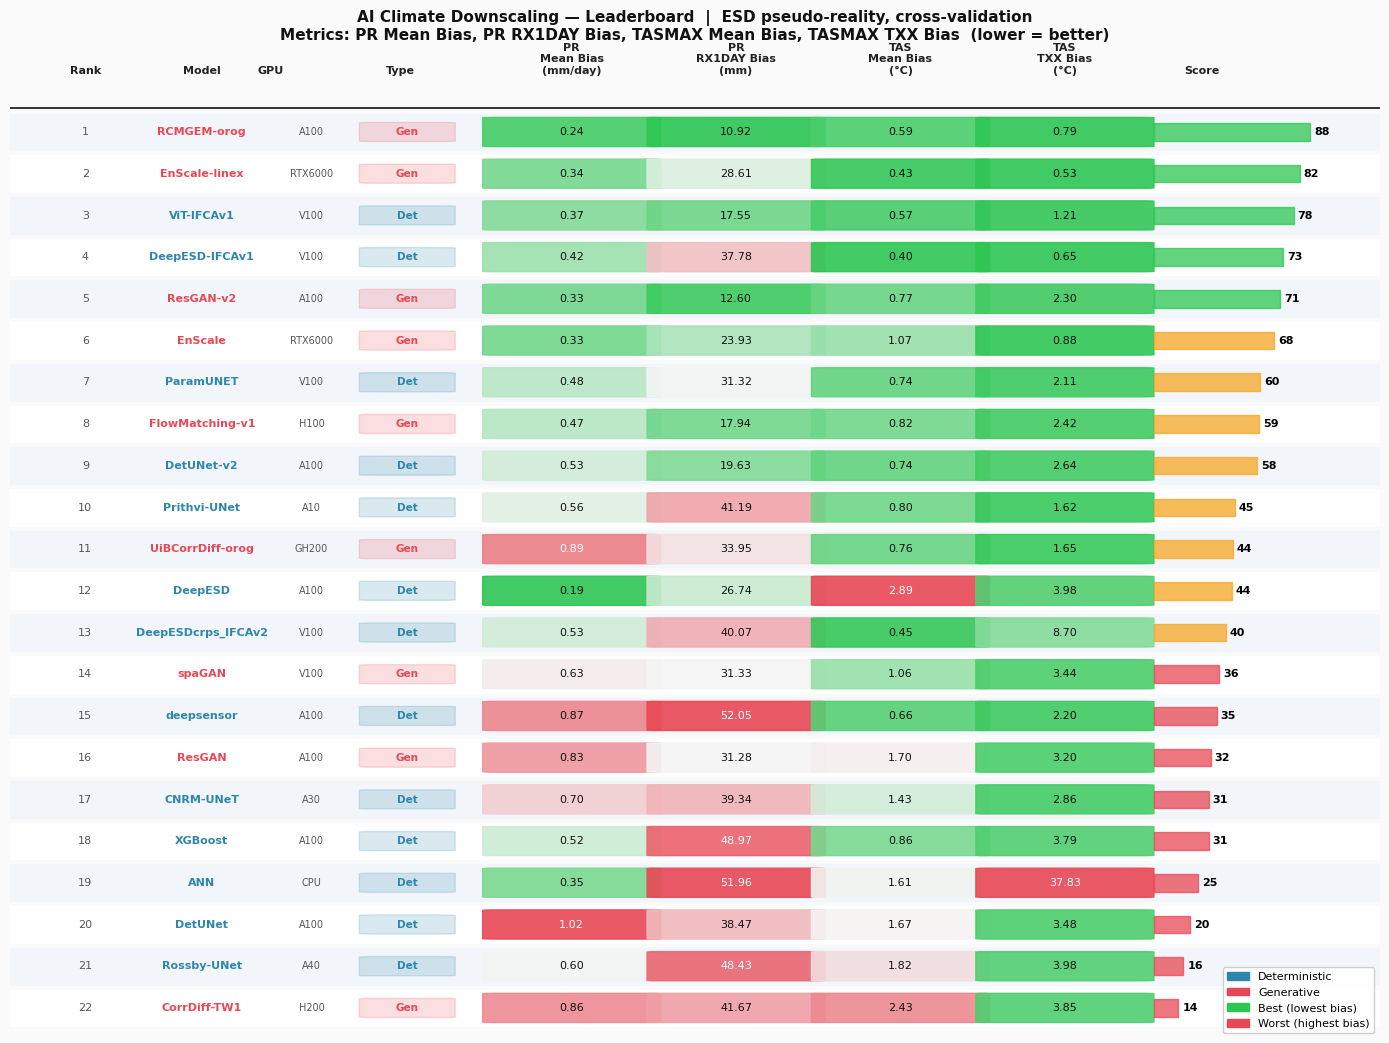

In [17]:
#fig.savefig(os.path.join(OUT_DIR, "fig2_params_vs_perf.png"), dpi=160, bbox_inches="tight")
#plt.close()
#print("  → fig2_params_vs_perf.png")

# ──────────────────────────────────────────────────────────────────────────────
# 7.  FIGURE 3 — Leaderboard (all 4 bias metrics, colour-coded)
# ──────────────────────────────────────────────────────────────────────────────
print("Building Figure 3: Leaderboard …")

df_lb = df.sort_values("perf_score", ascending=True).reset_index(drop=True)
n = len(df_lb)

METRIC_DISP = [
    ("pr_mb",     "PR\nMean Bias\n(mm/day)"),
    ("pr_rx1day", "PR\nRX1DAY Bias\n(mm)"),
    ("tas_mb",    "TAS\nMean Bias\n(°C)"),
    ("tas_txx",   "TAS\nTXX Bias\n(°C)"),
]
X_CELLS = [0.41, 0.53, 0.65, 0.77]

fig, ax = plt.subplots(figsize=(14, 10.5))
fig.patch.set_facecolor("#FAFAFA")
ax.set_xlim(0, 1)
ax.set_ylim(-0.5, n + 1)
ax.axis("off")

# Header row
for x, (_, lbl) in zip(X_CELLS, METRIC_DISP):
    ax.text(x, n + 0.35, lbl, ha="center", va="bottom", fontsize=8, fontweight="bold", color="#222")
for x, lbl in [(0.055, "Rank"), (0.14, "Model"), (0.285, "Type"), (0.87, "Score"), (0.19, "GPU")]:
    ax.text(x, n + 0.35, lbl, ha="center", va="bottom", fontsize=8, fontweight="bold", color="#222")
ax.axhline(n - 0.42, color="#333", lw=1.4)

col_min = {c: df_lb[c].min() for c, _ in METRIC_DISP}
col_max = {c: df_lb[c].max() for c, _ in METRIC_DISP}

for i, row in df_lb.iterrows():
    y   = i
    bg  = "#FFFFFF" if i % 2 == 0 else "#F2F6FA"
    ax.add_patch(mpatches.Rectangle((0, y - 0.44), 1, 0.88, color=bg, zorder=0))

    # Rank
    ax.text(0.055, y, str(n - i), ha="center", va="center", fontsize=8, color="#555")

    # Model name
    ax.text(0.14, y, short(row["model"]), ha="center", va="center", fontsize=8,
            fontweight="bold", color=TYPE_COLOR[row["type"]])

    # GPU chip
    ax.text(0.22, y, row["gpu"], ha="center", va="center", fontsize=7, color="#555")

    # Type badge
    tc = TYPE_COLOR[row["type"]]
    ax.add_patch(mpatches.FancyBboxPatch((0.265, y - 0.22), 0.05, 0.44,
                 boxstyle="round,pad=0.01", color=tc, alpha=0.18))
    ax.text(0.29, y, row["type"], ha="center", va="center", fontsize=7.5,
            color=tc, fontweight="bold")

    # Metric cells
    for x, (col, _) in zip(X_CELLS, METRIC_DISP):
        v = row[col]
        norm_v = (v - col_min[col]) / (col_max[col] - col_min[col])
        cell_c = GOOD_BAD(norm_v)
        ax.add_patch(mpatches.FancyBboxPatch((x - 0.055, y - 0.34), 0.11, 0.68,
                     boxstyle="round,pad=0.01", color=cell_c, alpha=0.9))
        text_c = "#fff" if norm_v > 0.82 else "#111"
        ax.text(x, y, f"{v:.2f}", ha="center", va="center", fontsize=8, color=text_c)

    # Score bar
    sc  = row["perf_score"]
    bar = 0.13 * sc / 100
    bar_c = "#2dc653" if sc > 70 else ("#f5a623" if sc > 40 else "#e84855")
    ax.add_patch(mpatches.Rectangle((0.835, y - 0.21), bar, 0.42, color=bar_c, alpha=0.75))
    ax.text(0.835 + bar + 0.003, y, f"{sc:.0f}", ha="left", va="center", fontsize=8, fontweight="bold")

ax.text(0.5, n + 1.2,
        "AI Climate Downscaling — Leaderboard  |  ESD pseudo-reality, cross-validation\n"
        "Metrics: PR Mean Bias, PR RX1DAY Bias, TASMAX Mean Bias, TASMAX TXX Bias  (lower = better)",
        ha="center", fontsize=11, fontweight="bold", color="#111")

legend_els = [
    mpatches.Patch(color=TYPE_COLOR["Det"],  label="Deterministic"),
    mpatches.Patch(color=TYPE_COLOR["Gen"],  label="Generative"),
    mpatches.Patch(color="#2dc653", label="Best (lowest bias)"),
    mpatches.Patch(color="#e84855", label="Worst (highest bias)"),
]
ax.legend(handles=legend_els, loc="lower right", fontsize=8, framealpha=0.92,
          bbox_to_anchor=(1.0, -0.01))

plt.tight_layout()
#fig.savefig(os.path.join(OUT_DIR, "fig3_leaderboard.png"), dpi=160, bbox_inches="tight")
#plt.close()
#print("  → fig3_leaderboard.png")

In [12]:


# ──────────────────────────────────────────────────────────────────────────────
# 8.  FIGURE 4 — Inference time vs bias (bubble = compute, 4-panel)
# ──────────────────────────────────────────────────────────────────────────────
print("Building Figure 4: Inference time vs bias …")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(
    "Inference Time vs Bias Performance (ESD pseudo-reality, cross-validation AV)\n"
    "Bubble size = training compute (A100-equiv h)  |  Colour = model type",
    fontsize=12, fontweight="bold",
)
axes = axes.flatten()
df_inf = df[df["infer_s"].notna()].copy()

for ax, (ycol, ylabel, title) in zip(axes, metric_pairs):
    sub = df_inf[df_inf[ycol].notna()]
    sizes = 50 + 280 * (np.log1p(sub["a100_h"]) / np.log1p(sub["a100_h"].max()))
    ax.scatter(sub["infer_s"], sub[ycol],
               c=[TYPE_COLOR[t] for t in sub["type"]],
               s=sizes, edgecolors="k", linewidths=0.6, alpha=0.88, zorder=3)
    for _, r in sub.iterrows():
        ax.annotate(short(r["model"]), (r["infer_s"], r[ycol]),
                    fontsize=6.2, xytext=(4, 3), textcoords="offset points", color="#333")
    ax.set_xscale("log")
    ax.set_xlabel("Inference time (seconds / year, log scale)", fontsize=9)
    ax.set_ylabel(ylabel, fontsize=9)
    ax.set_title(title, fontweight="bold", fontsize=10)
    ax.invert_yaxis()

axes[0].legend(handles=type_legend(), title="Model type", fontsize=8, title_fontsize=9)
sz_h = [Line2D([0],[0], marker="o", color="w", markerfacecolor="#888",
               markersize=s, markeredgecolor="k", label=l)
        for s, l in [(5,"<1h"), (9,"~10h"), (13,"~100h")]]
axes[1].legend(handles=sz_h, title="Training compute", fontsize=8, title_fontsize=9)

plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "fig4_inference_vs_perf.png"), dpi=160, bbox_inches="tight")
plt.close()
print("  → fig4_inference_vs_perf.png")

# ──────────────────────────────────────────────────────────────────────────────
# 9.  TABLE 1 — Full performance & compute summary  (sorted by score)
# ──────────────────────────────────────────────────────────────────────────────
print("Building Table 1: Performance & compute summary …")

df_t1 = df.sort_values("perf_score", ascending=False).reset_index(drop=True)
df_t1.insert(0, "Rank", range(1, len(df_t1) + 1))

def fmt_params(val, est):
    if pd.isna(val):
        return "—"
    tag = "~" if est else ""
    if val < 1:
        return f"{tag}{val*1000:.0f}K"
    return f"{tag}{val:.0f}M"

def fmt_infer(x):
    if pd.isna(x): return "—"
    if x < 60:     return f"{x:.0f}s"
    if x < 3600:   return f"{x/60:.0f}min"
    return f"{x/3600:.1f}h"

T1_COLS = {
    "Rank":            "Rank",
    "model":           "Model",
    "type":            "Type",
    "institution":     "Institution",
    "gpu":             "GPU",
    "a100_h":          "Train\n(A100-h)",
    "params_display":  "Params",
    "infer_display":   "Infer/yr",
    "pr_mb":           "PR\nMean Bias",
    "pr_rx1day":       "PR\nRX1DAY",
    "tas_mb":          "TAS\nMean Bias",
    "tas_txx":         "TAS\nTXX",
    "perf_score":      "Score",
}

df_t1["params_display"] = df_t1.apply(lambda r: fmt_params(r["params_M"], r["params_est"]), axis=1)
df_t1["infer_display"]  = df_t1["infer_s"].apply(fmt_infer)
df_t1["a100_h"]         = df_t1["a100_h"].apply(lambda x: f"{x:.2f}")
for col in ["pr_mb","pr_rx1day","tas_mb","tas_txx"]:
    df_t1[col] = df_t1[col].apply(lambda x: f"{x:.2f}")
df_t1["perf_score"] = df_t1["perf_score"].apply(lambda x: f"{x:.1f}")

fig, ax = plt.subplots(figsize=(22, 11))
fig.patch.set_facecolor("#FAFAFA")
ax.axis("off")

tbl = ax.table(
    cellText=df_t1[list(T1_COLS.keys())].values,
    colLabels=list(T1_COLS.values()),
    loc="center", cellLoc="center",
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(8)
tbl.scale(1, 1.55)

for j in range(len(T1_COLS)):
    tbl[(0, j)].set_facecolor("#2c3e50")
    tbl[(0, j)].set_text_props(color="white", fontweight="bold")

BIAS_IDX = [8, 9, 10, 11]
BIAS_COLS_RAW = ["pr_mb", "pr_rx1day", "tas_mb", "tas_txx"]
# Recompute numeric range from df for colouring
bias_data = df.sort_values("perf_score", ascending=False).reset_index(drop=True)
for ci, rc in zip(BIAS_IDX, BIAS_COLS_RAW):
    vals = bias_data[rc].values
    mn, mx = vals.min(), vals.max()
    for ri in range(len(df_t1)):
        nv = (vals[ri] - mn) / (mx - mn)
        tbl[(ri+1, ci)].set_facecolor(GOOD_BAD(nv))
        tbl[(ri+1, ci)].set_text_props(color="#fff" if nv > 0.8 else "#111")

TYPE_IDX = 2
for ri, row in bias_data.iterrows():
    tc = TYPE_COLOR[row["type"]]
    tbl[(ri+1, TYPE_IDX)].set_facecolor(tc)
    tbl[(ri+1, TYPE_IDX)].set_text_props(color="white", fontweight="bold")
    for ci in range(len(T1_COLS)):
        if ci not in BIAS_IDX and ci != TYPE_IDX:
            tbl[(ri+1, ci)].set_facecolor("#FFFFFF" if ri % 2 == 0 else "#EEF3F8")

ax.set_title(
    "AI Climate Downscaling — Performance & Compute Summary  |  ESD pseudo-reality, CV average across ALPS / NZ / SA\n"
    "Sorted by composite score (100 = best).  ~ = estimated parameter count.",
    fontsize=10, fontweight="bold", pad=8,
)
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "table1_performance_summary.png"), dpi=150, bbox_inches="tight")
plt.close()
print("  → table1_performance_summary.png")

# ──────────────────────────────────────────────────────────────────────────────
# 10.  TABLE 2 — Compute efficiency breakdown  (sorted by A100 hours)
# ──────────────────────────────────────────────────────────────────────────────
print("Building Table 2: Compute breakdown …")

df_t2 = df.copy()
df_t2["A100-equiv h"] = df_t2["a100_h"].apply(lambda x: f"{x:.2f}")
df_t2["# GPUs"]       = df_t2["n_gpu"].astype(int).astype(str)
df_t2["Raw train (h)"]= df_t2["train_h"].apply(lambda x: f"{x:.2f}")
df_t2["Params"]       = df_t2.apply(lambda r: fmt_params(r["params_M"], r["params_est"]), axis=1)
df_t2["Infer/yr"]     = df_t2["infer_s"].apply(fmt_infer)
df_t2["Score"]        = df_t2["perf_score"].apply(lambda x: f"{x:.1f}")
df_t2 = df_t2.sort_values("a100_h").reset_index(drop=True)
df_t2.insert(0, "Rank\n(compute)", range(1, len(df_t2)+1))

T2_COLS = ["Rank\n(compute)","model","type","institution","gpu","# GPUs",
           "Raw train (h)","A100-equiv h","Params","Infer/yr","Score"]

fig, ax = plt.subplots(figsize=(20, 11))
fig.patch.set_facecolor("#FAFAFA")
ax.axis("off")

tbl2 = ax.table(
    cellText=df_t2[T2_COLS].values,
    colLabels=[c.replace("\n"," | ") for c in T2_COLS],
    loc="center", cellLoc="center",
)
tbl2.auto_set_font_size(False)
tbl2.set_fontsize(8)
tbl2.scale(1, 1.55)

for j in range(len(T2_COLS)):
    tbl2[(0, j)].set_facecolor("#2c3e50")
    tbl2[(0, j)].set_text_props(color="white", fontweight="bold")

score_vals = df_t2["Score"].astype(float).values
for ri in range(len(df_t2)):
    for ci in range(len(T2_COLS)):
        bg = "#FFFFFF" if ri % 2 == 0 else "#EEF3F8"
        tbl2[(ri+1, ci)].set_facecolor(bg)
    # Score column (last): green=best
    sc = score_vals[ri] / 100
    tbl2[(ri+1, len(T2_COLS)-1)].set_facecolor(GOOD_BAD(1 - sc))
    tbl2[(ri+1, len(T2_COLS)-1)].set_text_props(color="#fff" if sc > 0.82 else "#111")
    # Type column
    tc = TYPE_COLOR[df_t2.iloc[ri]["type"]]
    tbl2[(ri+1, 2)].set_facecolor(tc)
    tbl2[(ri+1, 2)].set_text_props(color="white", fontweight="bold")

ax.set_title(
    "Compute Efficiency Breakdown — sorted by A100-equivalent GPU-hours (lowest = top)\n"
    "~ = estimated parameter count.  Score = composite rank across 4 bias metrics (100 = best).",
    fontsize=10, fontweight="bold", pad=8,
)
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "table2_compute_breakdown.png"), dpi=150, bbox_inches="tight")
plt.close()
print("  → table2_compute_breakdown.png")

print(f"\n✓  All outputs written to: {OUT_DIR}")

SyntaxError: invalid syntax (1550255560.py, line 31)